# Stage 4a: light users without retraining (Cor. 2, plan Step G items 1–4), Enron, GPT-Neo 125M
**Plan:** section 4 row 4, first part. Post-processing of Stage 2 (10 main seeds); no GPU. Cap retraining (Step G.6) is Stage 4b, not decided yet.

Per seed, m, draw and statistic: threshold = 95% quantile of the statistic among non-member users (FPR γ = 5%); a member is
detected if above it. Members are binned by k_u (training docs) and α_u (share of the training set).
**Cor. 2 prediction:** T̂ stays near chance (TPR ≈ γ) for light users at any m.

**Caveat:** after the 150+32 filter every Enron user has k_u ≥ 114, so there are no truly light users here; this stage compares
lighter with heavier users. With ~90 non-members, the 5% threshold rests on the top ~4–5 non-members, so per-seed TPRs are noisy.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import analysis as A
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
# categorical slots 1-3 (same as Stage 2); ordered groups use one blue ramp, light -> dark
COL = {"T": "#2a78d6", "S_cat": "#eb6834", "Agg": "#1baf7a"}
MRK = {"T": "o", "S_cat": "s", "Agg": "^"}
NAME = {"T": "T̂ (mean)", "S_cat": "S_cat", "Agg": "aggregator (EVAL)"}
RAMP = ["#a9cdf2", "#6aa6e8", "#2a78d6", "#174a8c"]
uv = A.S2.cached_user_values()   # Stage 2 per-user statistics (cached in Stage2/results/_user_values.csv.gz)
print(uv.groupby("run").seed.nunique().to_dict(), "models;", uv.user.nunique(), "users")

{'main': 10, 'null': 1} models; 175 users


In [2]:
det = A.member_detection(uv)
ek = A.k_bins(uv); ea = np.quantile(det.alpha_u, [0, .25, .5, .75, 1])
print("k_u bin edges:", ek.round(0), " alpha_u bin edges:", ea.round(4))
tk = A.tpr_by_bin(det, ek); ta = A.tpr_by_bin(det, ea, by="alpha_u")
display(tk.pivot_table(index="m", columns=["stat", "bin"], values="tpr", observed=True).round(3))

k_u bin edges: [ 114.  164.  294.  566. 3925.]  alpha_u bin edges: [0.0021 0.0038 0.0065 0.0122 0.0968]


stat              Agg                                                          S_cat                                                              T                                              
bin  (113.999, 163.5] (163.5, 294.0] (294.0, 565.5] (565.5, 3925.0] (113.999, 163.5] (163.5, 294.0] (294.0, 565.5] (565.5, 3925.0] (113.999, 163.5] (163.5, 294.0] (294.0, 565.5] (565.5, 3925.0]
m                                                                                                                                                                                                
1               0.240          0.205          0.314           0.331            0.317          0.258          0.277           0.268            0.317          0.258          0.277           0.268
2               0.319          0.254          0.384           0.444            0.327          0.320          0.362           0.379            0.328          0.310          0.346           0.368
4               0.254          0.294          0.396           0.379            0.367          0.394          0.405           0.380            0.358          0.390          0.405           0.377
8               0.300          0.292          0.389           0.406            0.382          0.376          0.435           0.382            0.383          0.374          0.392           0.342
16              0.411          0.349          0.422           0.417            0.507          0.401          0.456           0.419            0.483          0.399          0.437           0.380
32              0.366          0.340          0.395           0.452            0.512          0.397          0.463           0.451            0.431          0.367          0.403           0.360

## 1. TPR at 5% FPR vs m, by k_u quartile
Line: mean over seeds; dotted: chance (γ = 0.05).

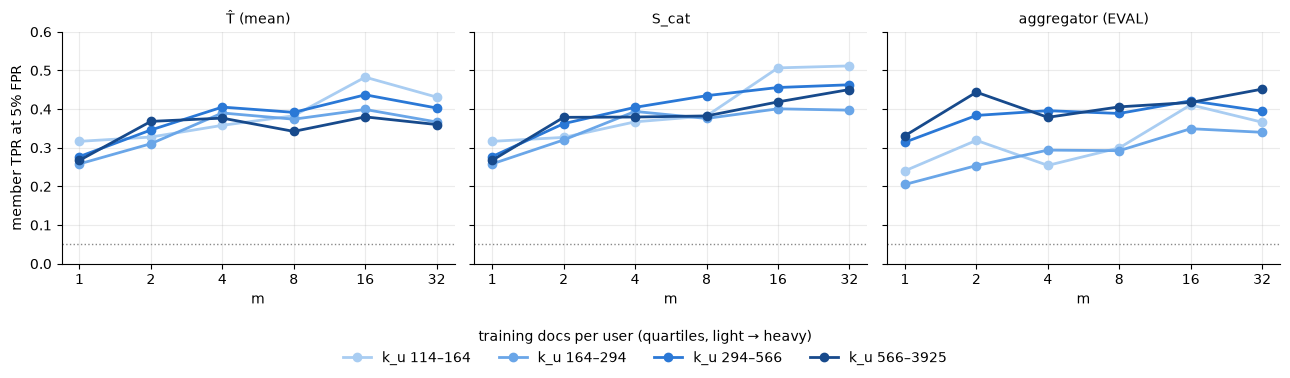

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, st in zip(axes, A.STATS):
    x = tk[tk.stat == st]
    for i, (b, g) in enumerate(x.groupby("bin", observed=True)):
        ax.plot(g.m, g.tpr, marker="o", color=RAMP[i], lw=2, ms=6, label=f"k_u {b.left:.0f}–{b.right:.0f}")
    ax.axhline(A.GAMMA, color="#888", lw=1, ls=":")
    ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8, 16, 32], [1, 2, 4, 8, 16, 32]); ax.set_xlabel("m")
    ax.set_title(NAME[st], fontsize=10)
axes[0].set_ylabel("member TPR at 5% FPR"); axes[0].set_ylim(0, 0.6)
hs, ls = axes[0].get_legend_handles_labels()
fig.legend(hs, ls, frameon=False, loc="lower center", ncol=4, title="training docs per user (quartiles, light → heavy)")
plt.tight_layout(rect=(0, 0.14, 1, 1)); plt.show()

## 2. By α_u (share of the training set) and rank correlations

In [4]:
display(ta[ta.m.isin([1, 8, 32])].round(3))
display(A.rank_corr(det).round(3))

,stat,m,bin,tpr,tpr_min,tpr_max,members_per_seed
0,Agg,1,"(0.0010799999999999998, 0.0038]",0.224,0.077,0.375,10.0
1,Agg,1,"(0.0038, 0.00647]",0.232,0.068,0.432,11.8
2,Agg,1,"(0.00647, 0.0122]",0.302,0.234,0.364,12.9
3,Agg,1,"(0.0122, 0.0968]",0.340,0.156,0.464,9.1
12,Agg,8,"(0.0010799999999999998, 0.0038]",0.289,0.150,0.500,10.0
13,Agg,8,"(0.0038, 0.00647]",0.308,0.159,0.455,11.8
14,Agg,8,"(0.00647, 0.0122]",0.380,0.273,0.500,12.9
15,Agg,8,"(0.0122, 0.0968]",0.404,0.200,0.636,9.1
20,Agg,32,"(0.0010799999999999998, 0.0038]",0.375,0.133,0.600,10.0
21,Agg,32,"(0.0038, 0.00647]",0.362,0.091,0.556,11.8


,stat,m,rho_k_u,rho_alpha_u,rho_k_u_min,rho_k_u_max
0,Agg,1,0.131,0.131,-0.175,0.459
1,Agg,2,0.196,0.196,0.027,0.464
2,Agg,4,0.184,0.184,0.015,0.352
3,Agg,8,0.152,0.152,-0.045,0.400
4,Agg,16,0.118,0.118,-0.047,0.295
5,Agg,32,0.106,0.106,-0.028,0.253
6,S_cat,1,-0.006,-0.006,-0.148,0.242
7,S_cat,2,0.051,0.051,-0.113,0.217
8,S_cat,4,0.016,0.016,-0.130,0.184
9,S_cat,8,0.005,0.005,-0.079,0.103


## Notes (2026-11-25)
- **TPR vs k_u / α_u:** no dependence. T̂ at m = 32: TPR at 5% FPR 0.43 / 0.37 / 0.40 / 0.36 from the lightest to the heaviest k_u quartile (k_u 114–164 … 566–3925); Spearman(k_u, T̂) among members ≈ −0.02 (range −0.09 to 0.09 over seeds); same for α_u. S_cat: same picture. The aggregator alone shows a weak trend (ρ ≈ 0.1–0.2; lighter quartiles 0.34–0.37 vs 0.40–0.45 at m = 32).
- **Cor. 2 prediction (light users near chance for T̂):** not testable here. Every Enron user has k_u ≥ 114 (α_u ≥ 0.2%), and over that range lighter users are as detectable as heavy ones (TPR ≈ 0.3–0.5 ≫ γ = 0.05). Light users only exist with caps.
- **Decision:** Stage 4b (cap retraining) is needed to test Cor. 2; cap grid and seeds to be decided with the user.